[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bihjane/data-science-and-ai-k-12-teaching-tools/blob/main/intelligent-futures-free-courses/colab-notebooks/01_first_model_linear_regression.ipynb)

# Your first model: predicting Olympic sprint times
**Level:** beginner · **Time:** 45 minutes · **Model:** linear regression

**Question:** The men's Olympic 100 m has been run since 1896. Can a model predict the winning time in 2028, and where does that model stop making sense?

You will go through every step of building a model:

| Step | What you do |
|---|---|
| 1 | Load the data |
| 2 | Explore it with a graph |
| 3 | Build a model by hand |
| 4 | Let the computer find the best line |
| 5 | Measure the error |
| 6 | Test the model on years it never saw |
| 7 | Make a prediction and check its limits |

## How to use this notebook
1. Click **Open in Colab** above, or upload this file at [colab.research.google.com](https://colab.research.google.com) (File > Upload notebook).
2. Run each code cell in order with **Shift + Enter**.
3. Before running a cell, **predict** what it will show. After running it, check your prediction.
4. Try the **Your turn** tasks at the end of each step.

No installs or downloads are needed. Everything runs free in your browser.

## Step 1. Load the data
Winning times (seconds) from olympics.com. There were no Games in 1916, 1940 and 1944.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

years = [1896,1900,1904,1908,1912,1920,1924,1928,1932,1936,1948,1952,1956,1960,1964,
         1968,1972,1976,1980,1984,1988,1992,1996,2000,2004,2008,2012,2016,2020,2024]
times = [12.0,11.0,11.0,10.8,10.8,10.8,10.6,10.8,10.3,10.3,10.3,10.4,10.5,10.2,10.0,
         9.95,10.14,10.06,10.25,9.99,9.92,9.96,9.84,9.87,9.85,9.69,9.63,9.81,9.80,9.79]

df = pd.DataFrame({"year": years, "time": times})
print(df.shape)      # (rows, columns)
df.head()

(30, 2)


,year,time
0,1896,12.0
1,1900,11.0
2,1904,11.0
3,1908,10.8
4,1912,10.8


**Your turn:** How many Olympic Games are in the table? What is the fastest time and when was it run? Try `df.describe()` and `df.sort_values('time').head(3)`.

## Step 2. Explore with a graph
A model is only useful if there is a pattern to model. Look before you fit.

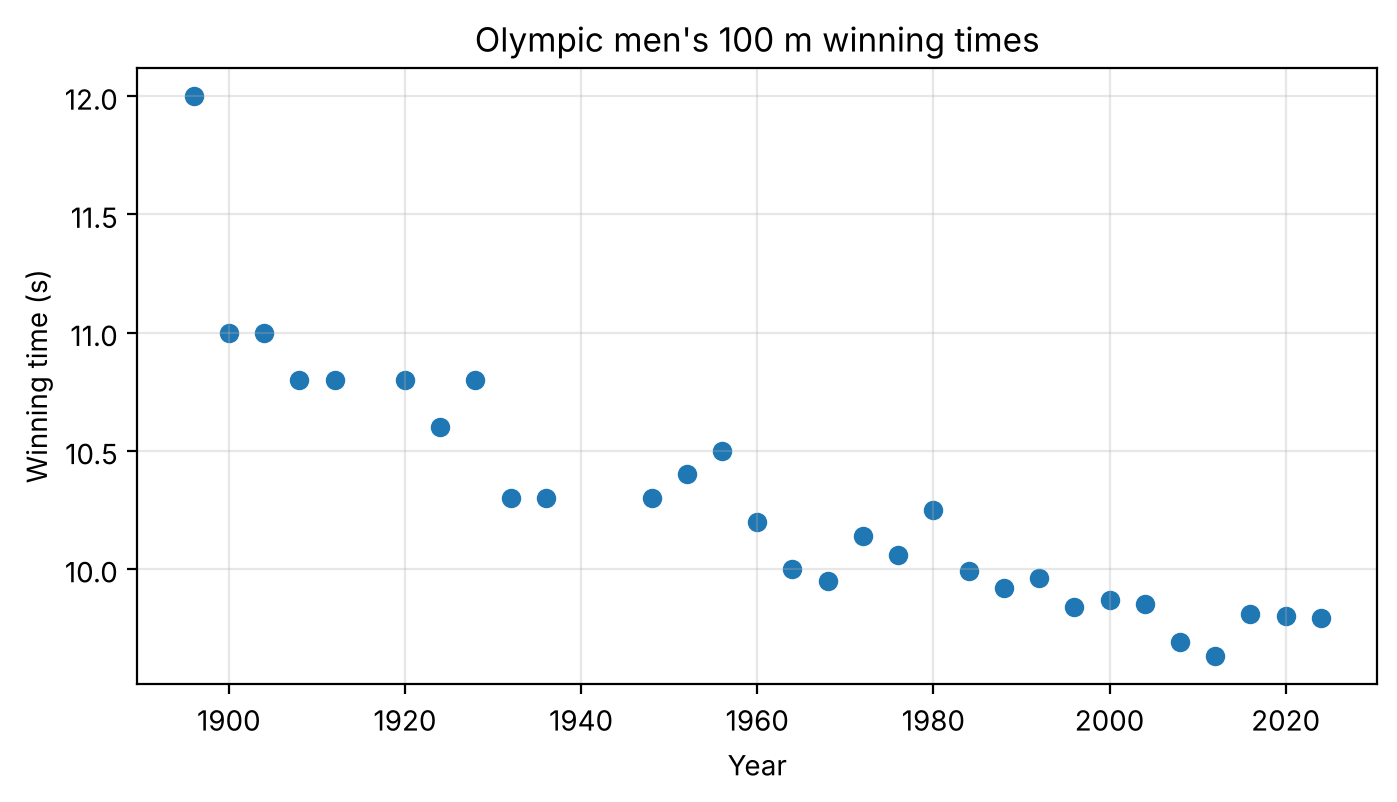

In [2]:
plt.figure(figsize=(8,4))
plt.scatter(df.year, df.time)
plt.xlabel("Year"); plt.ylabel("Winning time (s)")
plt.title("Olympic men's 100 m winning times")
plt.grid(alpha=0.3)
plt.show()

**Your turn:** Describe the trend in one sentence. Is it getting faster at a steady rate?

## Step 3. Build a model by hand
A linear model is `time = m × year + b`. Change `m` and `b` until the line fits well. This is exactly what the computer will do in Step 4, only faster.

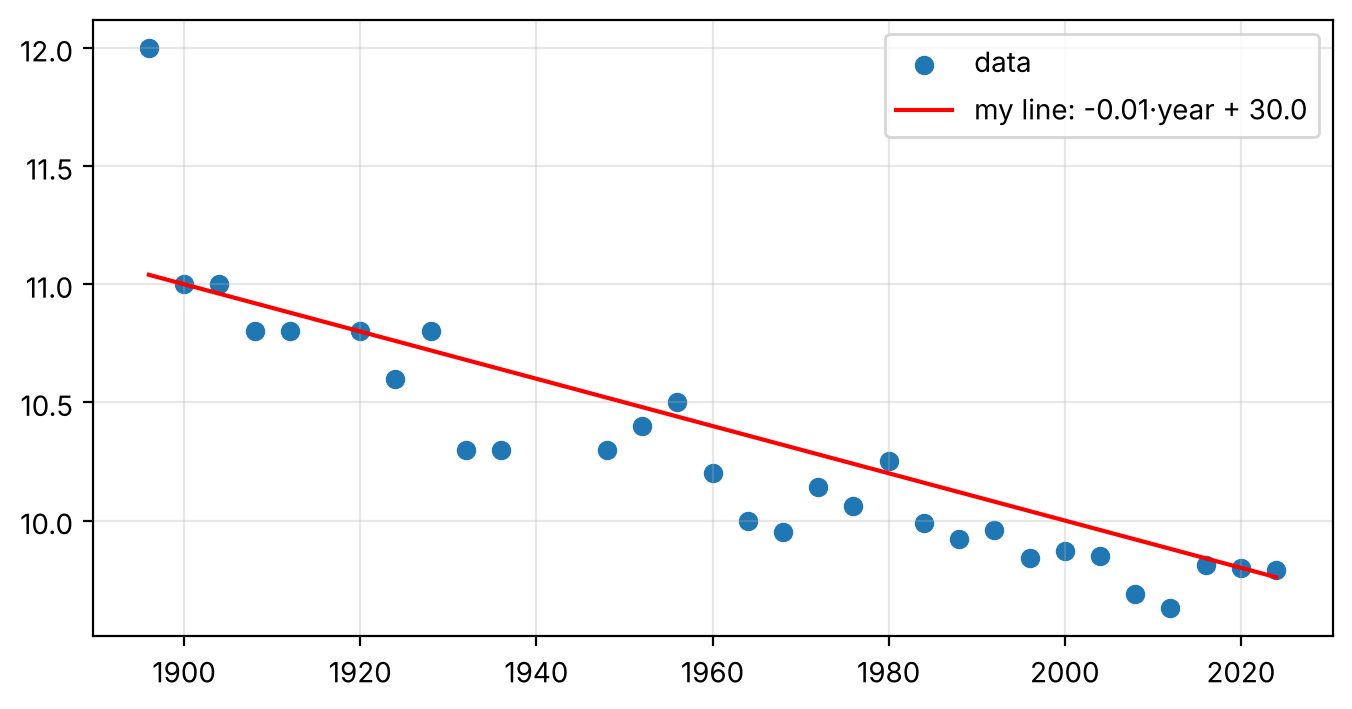

Mean squared error of my line: 0.0642


In [3]:
m = -0.01   # slope: seconds per year
b = 30.0    # intercept

guess = m * df.year + b
plt.figure(figsize=(8,4))
plt.scatter(df.year, df.time, label="data")
plt.plot(df.year, guess, color="red", label=f"my line: {m}·year + {b}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

error = ((df.time - guess) ** 2).mean()
print("Mean squared error of my line:", round(error, 4))

**Your turn:** Try at least three pairs of `m` and `b`. Which pair gives the smallest error?

## Step 4. Let the computer find the best line
`scikit-learn` finds the slope and intercept with the smallest possible squared error (least squares).

In [4]:
from sklearn.linear_model import LinearRegression

X = df[["year"]]     # inputs (features) must be a table
y = df["time"]       # output (target)

model = LinearRegression()
model.fit(X, y)

print("slope m     =", round(model.coef_[0], 5), "seconds per year")
print("intercept b =", round(model.intercept_, 2))

slope m     = -0.01185 seconds per year
intercept b = 33.54


The slope is about **-0.012 s per year**, roughly 0.05 s faster at each Olympics.

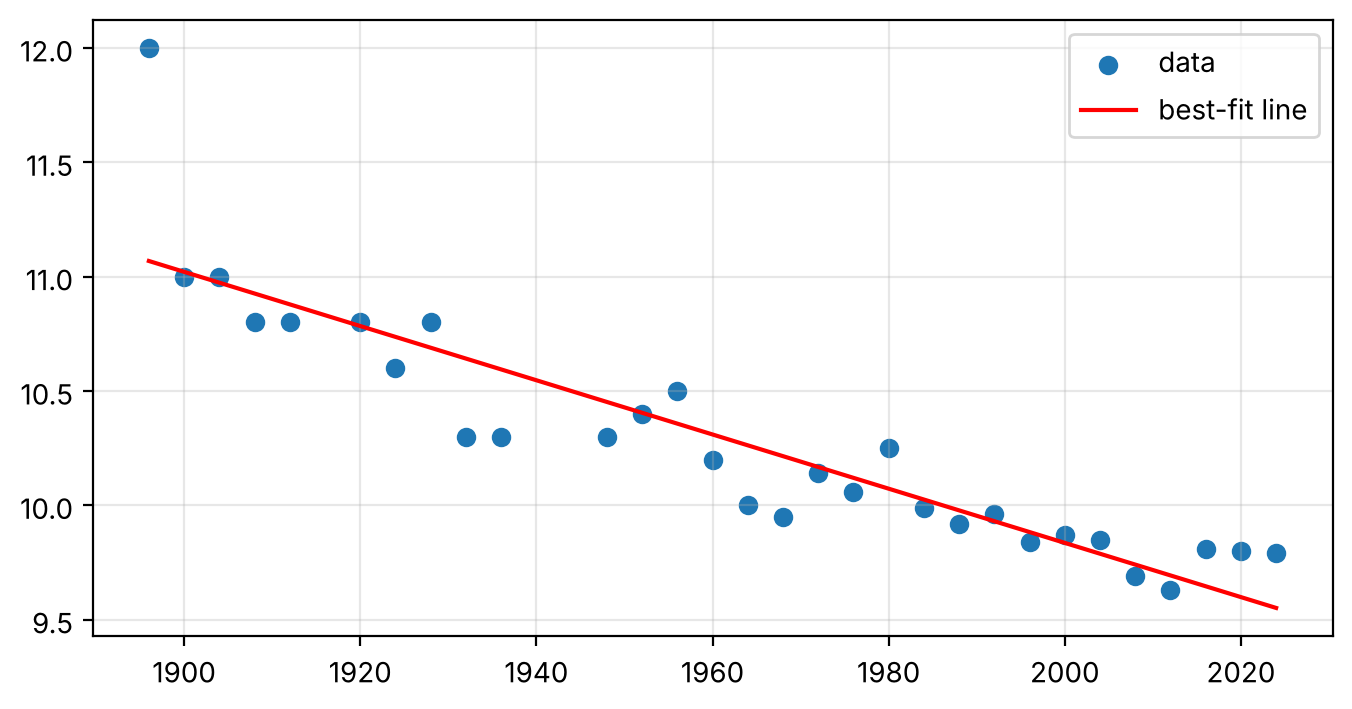

In [5]:
df["predicted"] = model.predict(X)
plt.figure(figsize=(8,4))
plt.scatter(df.year, df.time, label="data")
plt.plot(df.year, df.predicted, color="red", label="best-fit line")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Step 5. Measure the error
A **residual** is actual minus predicted. Small, random residuals mean a good fit.

Mean absolute error: 0.142 seconds
R squared: 0.809


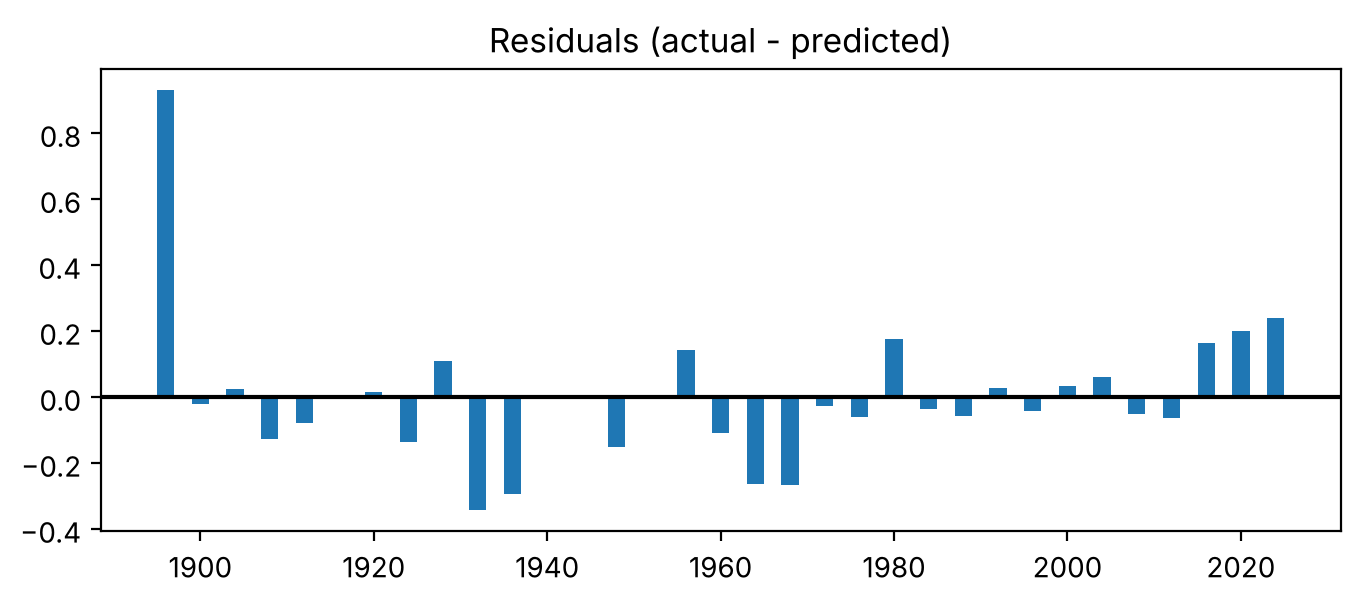

In [6]:
from sklearn.metrics import mean_absolute_error, r2_score

df["residual"] = df.time - df.predicted
print("Mean absolute error:", round(mean_absolute_error(df.time, df.predicted), 3), "seconds")
print("R squared:", round(r2_score(df.time, df.predicted), 3))

plt.figure(figsize=(8,3))
plt.bar(df.year, df.residual, width=2)
plt.axhline(0, color="black")
plt.title("Residuals (actual - predicted)"); plt.show()

**Your turn:** Which Games had the biggest positive residual? What might explain it? (Hint: early times were hand-timed.)

## Step 6. Test on years the model never saw
A fair test hides some data during training. Train on Games up to 2000, then test on 2004 to 2024.

In [7]:
train = df[df.year <= 2000]
test  = df[df.year > 2000]

m2 = LinearRegression().fit(train[["year"]], train["time"])
test_pred = m2.predict(test[["year"]])

print(pd.DataFrame({"year": test.year, "actual": test.time, "predicted": test_pred.round(2)}))
print("Test error (MAE):", round(mean_absolute_error(test.time, test_pred), 3), "seconds")

    year  actual  predicted
24  2004    9.85       9.68
25  2008    9.69       9.63
26  2012    9.63       9.57
27  2016    9.81       9.52
28  2020    9.80       9.47
29  2024    9.79       9.41
Test error (MAE): 0.215 seconds


## Step 7. Predict, then check the limits

In [8]:
for yr in [2028, 2100, 2500]:
    print(yr, "->", round(model.predict(pd.DataFrame({"year": [yr]}))[0], 2), "s")

zero_year = -model.intercept_ / model.coef_[0]
print("The line reaches 0 seconds in about the year", int(zero_year))

2028 -> 9.5 s
2100 -> 8.65 s
2500 -> 3.91 s
The line reaches 0 seconds in about the year 2829


A 0-second race is impossible. Every model has a **domain** where it makes sense. Straight lines are good for short-range predictions, not for the far future.

## Summary
You loaded data, explored it, fit a model by hand and by computer, measured error, tested on unseen data and found the model's limits. These are the same steps used for every machine learning model.

## Your turn: extensions
1. Refit using only 1960 onward. Does the 2028 prediction change?
2. Add the women's 100 m winning times and find when the two lines cross.
3. Try a curve that levels off: `from sklearn.preprocessing import PolynomialFeatures`.

---
*Intelligent Futures · Dr. Bih Janet Shufor · Free for classroom use with attribution.*